# 📊 Dataset Information

**Note:** The dataset for this project is **not included in this repository** to keep the repository lightweight.  

You can download the dataset from **Kaggle** using the link below:  

[Download The Sleep Health Lifestyle Dataset](https://www.kaggle.com/datasets/vedauv/sleep-health-and-lifestyle-10000-people/data?select=sleep_health_lifestyle.csv)  

Please make sure to place the downloaded CSV file in the same directory as this notebook before running any code.

# Importing

## Import Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

## Import CSV And convert to DataFrame

In [2]:
df = pd.read_csv('sleep_health_lifestyle.csv')

# Preprocessing

## Frist five row

In [3]:
df.head()

,person_id,age,gender,occupation,work_hours_week,shift_work,stress_level,bmi,smoker,alcohol_drinks_week,caffeine_mg_day,screen_min_before_bed,exercise_min_week,steps_per_day,resting_heart_rate,bedtime_hour,sleep_hours,sleep_quality,daytime_fatigue_score,sleep_disorder
0,SL00001,49,Male,Nurse,48.4,0,7,22.5,0,3,235,72,67,1866,64,21.9,6.0,6,49.0,0
1,SL00002,50,Male,Software Engineer,31.7,0,3,24.7,0,1,118,99,72,5952,66,22.3,6.9,8,34.1,0
2,SL00003,26,Female,Driver,57.9,0,5,24.8,0,3,55,34,190,9096,58,21.8,8.5,10,12.0,0
3,SL00004,36,Female,Other,29.5,0,6,25.5,0,2,140,9,63,5412,81,24.1,7.7,7,41.5,0
4,SL00005,18,Female,Teacher,40.7,0,6,34.2,1,3,20,52,201,5424,72,22.4,7.6,10,19.9,0


## last Five row

In [4]:
df.tail()

,person_id,age,gender,occupation,work_hours_week,shift_work,stress_level,bmi,smoker,alcohol_drinks_week,caffeine_mg_day,screen_min_before_bed,exercise_min_week,steps_per_day,resting_heart_rate,bedtime_hour,sleep_hours,sleep_quality,daytime_fatigue_score,sleep_disorder
9995,SL09996,37,Female,Other,27.0,0,5,26.7,0,4,129,45,28,6251,78,22.8,6.9,8,45.8,0
9996,SL09997,35,Female,Other,39.3,0,7,26.2,1,5,362,36,98,12405,74,23.2,6.3,6,58.7,1
9997,SL09998,44,Male,Doctor,30.8,1,7,23.7,0,2,54,30,263,9230,63,23.7,5.6,5,65.1,0
9998,SL09999,36,Male,Other,54.5,0,2,23.7,1,2,714,73,600,11769,60,24.3,7.0,6,23.8,1
9999,SL10000,31,Female,Other,36.1,0,4,26.9,0,3,118,56,53,8759,59,23.8,6.4,6,32.6,0


## Shape of our dataset

In [5]:
df.shape

(10000, 20)

## List out all columns

In [6]:
df.columns

Index(['person_id', 'age', 'gender', 'occupation', 'work_hours_week',
       'shift_work', 'stress_level', 'bmi', 'smoker', 'alcohol_drinks_week',
       'caffeine_mg_day', 'screen_min_before_bed', 'exercise_min_week',
       'steps_per_day', 'resting_heart_rate', 'bedtime_hour', 'sleep_hours',
       'sleep_quality', 'daytime_fatigue_score', 'sleep_disorder'],
      dtype='object')

## Datatype of each columns

In [7]:
df.dtypes

person_id                 object
age                        int64
gender                    object
occupation                object
work_hours_week          float64
shift_work                 int64
stress_level               int64
bmi                      float64
smoker                     int64
alcohol_drinks_week        int64
caffeine_mg_day            int64
screen_min_before_bed      int64
exercise_min_week          int64
steps_per_day              int64
resting_heart_rate         int64
bedtime_hour             float64
sleep_hours              float64
sleep_quality              int64
daytime_fatigue_score    float64
sleep_disorder             int64
dtype: object

## Information of all Columns

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 20 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   person_id              10000 non-null  object 
 1   age                    10000 non-null  int64  
 2   gender                 10000 non-null  object 
 3   occupation             10000 non-null  object 
 4   work_hours_week        10000 non-null  float64
 5   shift_work             10000 non-null  int64  
 6   stress_level           10000 non-null  int64  
 7   bmi                    10000 non-null  float64
 8   smoker                 10000 non-null  int64  
 9   alcohol_drinks_week    10000 non-null  int64  
 10  caffeine_mg_day        10000 non-null  int64  
 11  screen_min_before_bed  10000 non-null  int64  
 12  exercise_min_week      10000 non-null  int64  
 13  steps_per_day          10000 non-null  int64  
 14  resting_heart_rate     10000 non-null  int64  
 15  bed

## Check Null Value

In [9]:
df.isnull().sum()

person_id                0
age                      0
gender                   0
occupation               0
work_hours_week          0
shift_work               0
stress_level             0
bmi                      0
smoker                   0
alcohol_drinks_week      0
caffeine_mg_day          0
screen_min_before_bed    0
exercise_min_week        0
steps_per_day            0
resting_heart_rate       0
bedtime_hour             0
sleep_hours              0
sleep_quality            0
daytime_fatigue_score    0
sleep_disorder           0
dtype: int64

## Check Dupicate Value

In [10]:
df.duplicated().sum()

np.int64(0)

## Summary

In [11]:
df.describe()

,age,work_hours_week,shift_work,stress_level,bmi,smoker,alcohol_drinks_week,caffeine_mg_day,screen_min_before_bed,exercise_min_week,steps_per_day,resting_heart_rate,bedtime_hour,sleep_hours,sleep_quality,daytime_fatigue_score,sleep_disorder
count,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,38.517600,42.049060,0.184800,5.01820,26.504260,0.139100,2.987000,153.788400,49.258000,119.247500,7450.92730,67.291700,23.248260,6.903690,6.862900,37.958620,0.250000
std,11.547789,10.033769,0.388155,1.97004,4.459443,0.346068,1.737393,103.660522,34.871981,84.170209,2579.37443,6.335868,1.015237,0.876401,1.351476,14.981357,0.433034
min,18.000000,6.900000,0.000000,1.00000,16.000000,0.000000,0.000000,1.000000,0.000000,0.000000,500.00000,42.000000,20.500000,3.600000,2.000000,0.000000,0.000000
25%,30.000000,35.200000,0.000000,4.00000,23.500000,0.000000,2.000000,78.000000,24.000000,58.000000,5713.75000,63.000000,22.500000,6.300000,6.000000,27.500000,0.000000
50%,38.000000,41.900000,0.000000,5.00000,26.500000,0.000000,3.000000,132.000000,41.000000,99.000000,7424.00000,67.000000,23.200000,6.900000,7.000000,37.200000,0.000000
75%,47.000000,48.800000,0.000000,6.00000,29.500000,0.000000,4.000000,205.000000,66.000000,161.000000,9201.00000,72.000000,23.900000,7.500000,8.000000,47.900000,0.250000
max,80.000000,80.000000,1.000000,10.00000,41.500000,1.000000,12.000000,800.000000,240.000000,600.000000,19329.00000,94.000000,26.900000,10.000000,10.000000,99.700000,1.000000


# EDA

In [12]:
def show_fig():
    plt.tight_layout()
    plt.show()

plot_no = 1

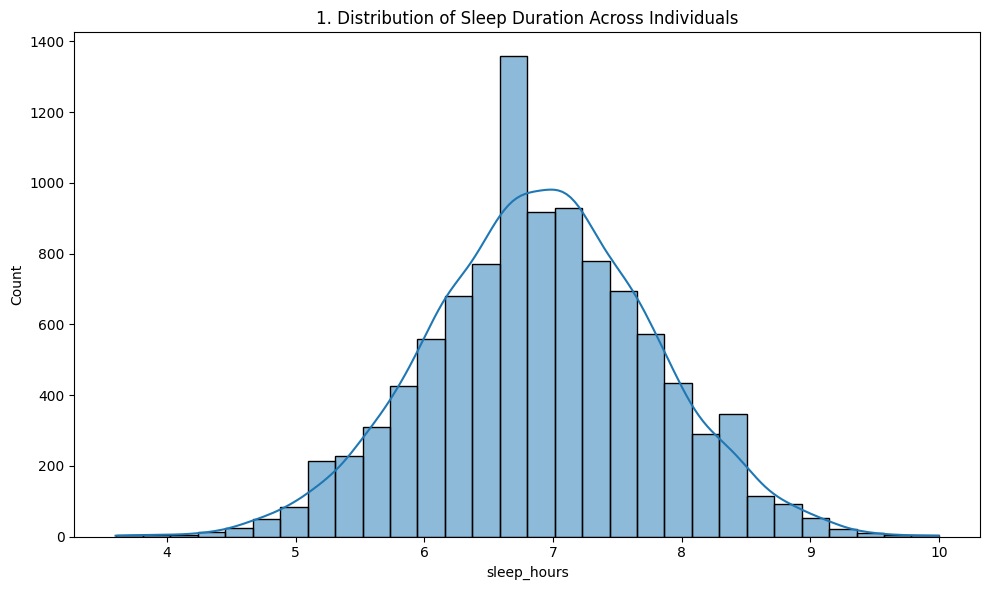

In [13]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='sleep_hours', kde=True, bins=30)
plt.title(f'{plot_no}. Distribution of Sleep Duration Across Individuals')
show_fig()
plot_no += 1

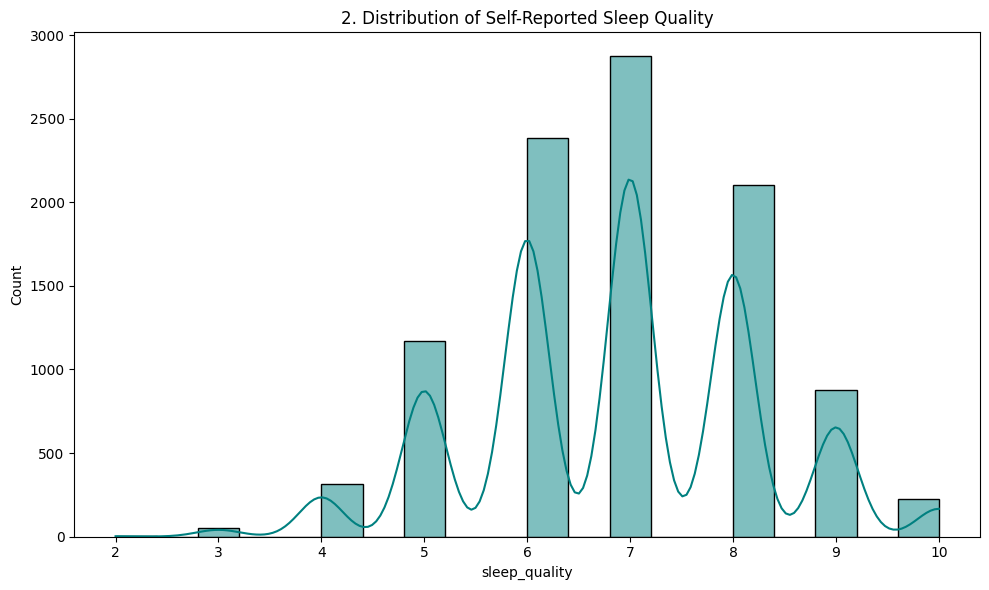

In [14]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='sleep_quality', kde=True, bins=20, color='teal')
plt.title(f'{plot_no}. Distribution of Self-Reported Sleep Quality')
show_fig()
plot_no += 1

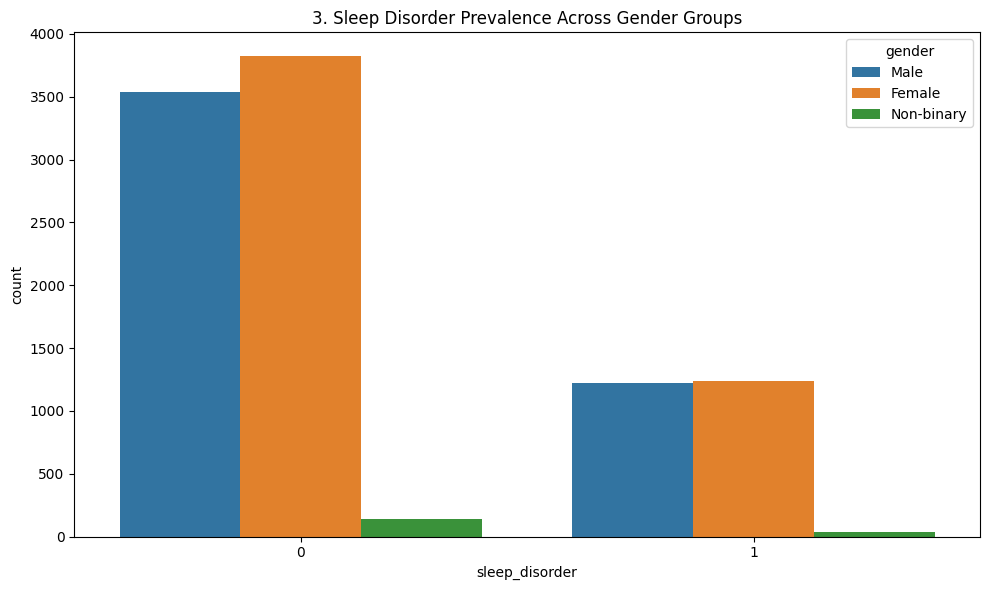

In [15]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='sleep_disorder', hue='gender')
plt.title(f'{plot_no}. Sleep Disorder Prevalence Across Gender Groups')
show_fig()
plot_no += 1

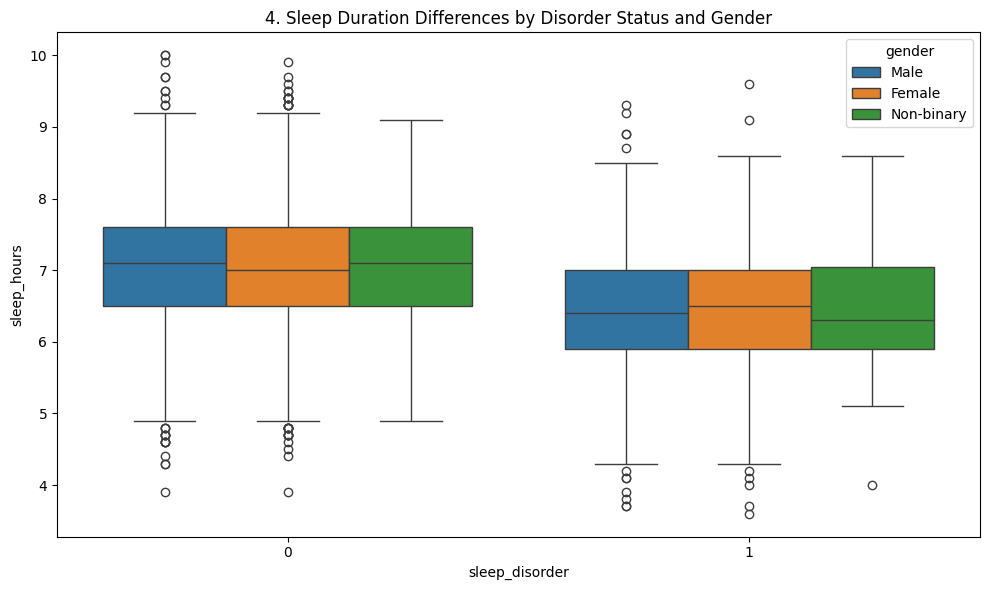

In [16]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='sleep_disorder', y='sleep_hours', hue='gender')
plt.title(f'{plot_no}. Sleep Duration Differences by Disorder Status and Gender')
show_fig()
plot_no += 1

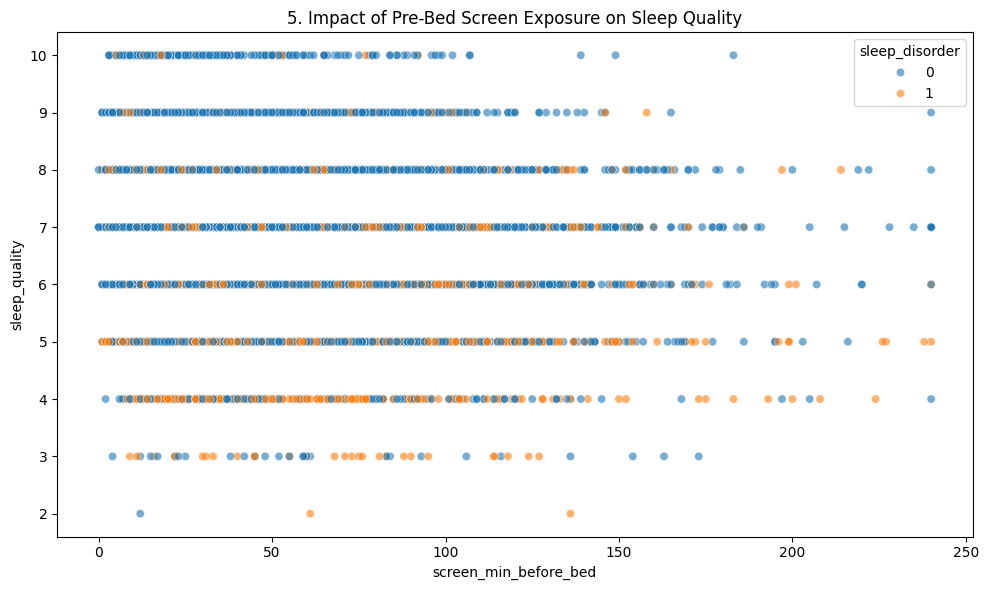

In [17]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='screen_min_before_bed', y='sleep_quality', hue='sleep_disorder', alpha=0.6)
plt.title(f'{plot_no}. Impact of Pre-Bed Screen Exposure on Sleep Quality')
show_fig()
plot_no += 1

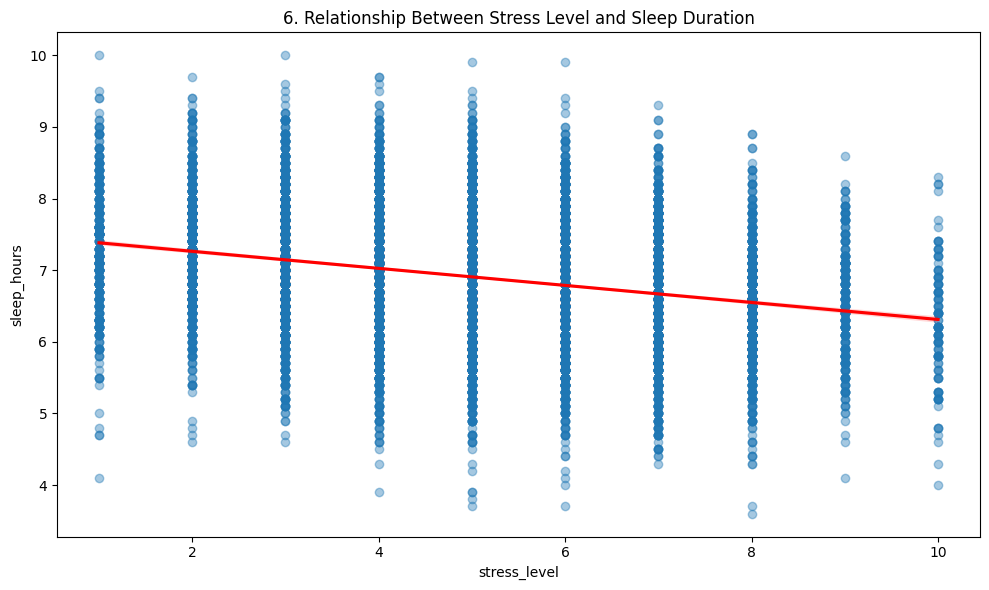

In [18]:
fig = plt.figure(figsize=(10,6))
sns.regplot(data=df, x='stress_level', y='sleep_hours', scatter_kws={'alpha':0.4}, line_kws={'color':'red'})
plt.title(f'{plot_no}. Relationship Between Stress Level and Sleep Duration')
show_fig()
plot_no += 1

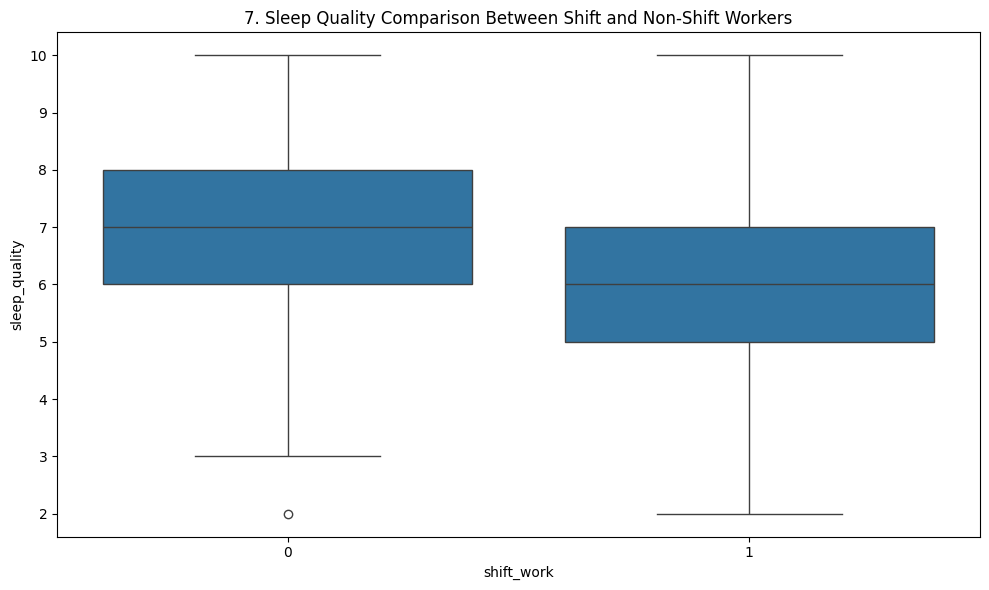

In [19]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='shift_work', y='sleep_quality')
plt.title(f'{plot_no}. Sleep Quality Comparison Between Shift and Non-Shift Workers')
show_fig()
plot_no += 1

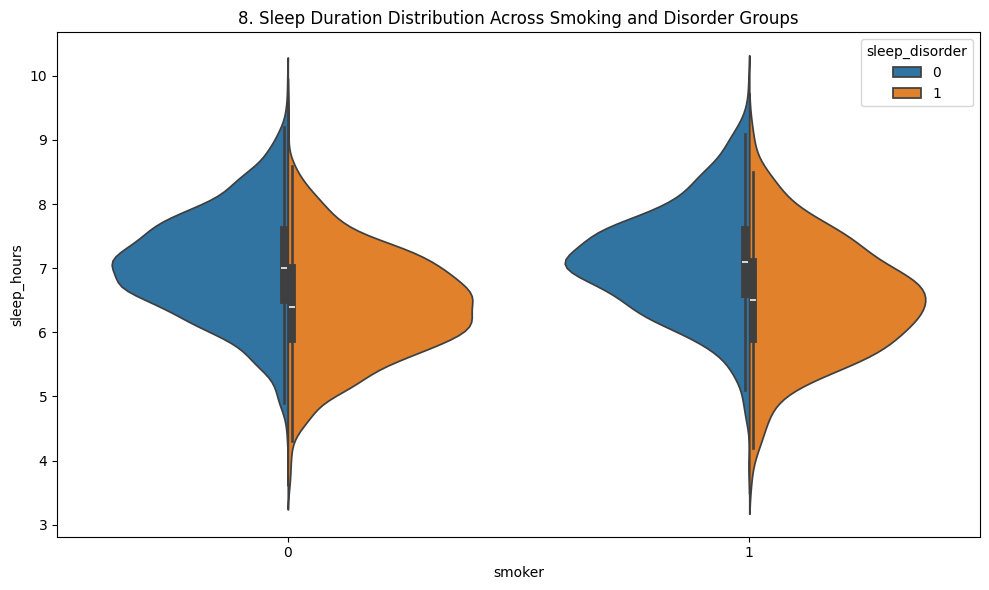

In [20]:
fig = plt.figure(figsize=(10,6))
sns.violinplot(data=df, x='smoker', y='sleep_hours', hue='sleep_disorder', split=True)
plt.title(f'{plot_no}. Sleep Duration Distribution Across Smoking and Disorder Groups')
show_fig()
plot_no += 1

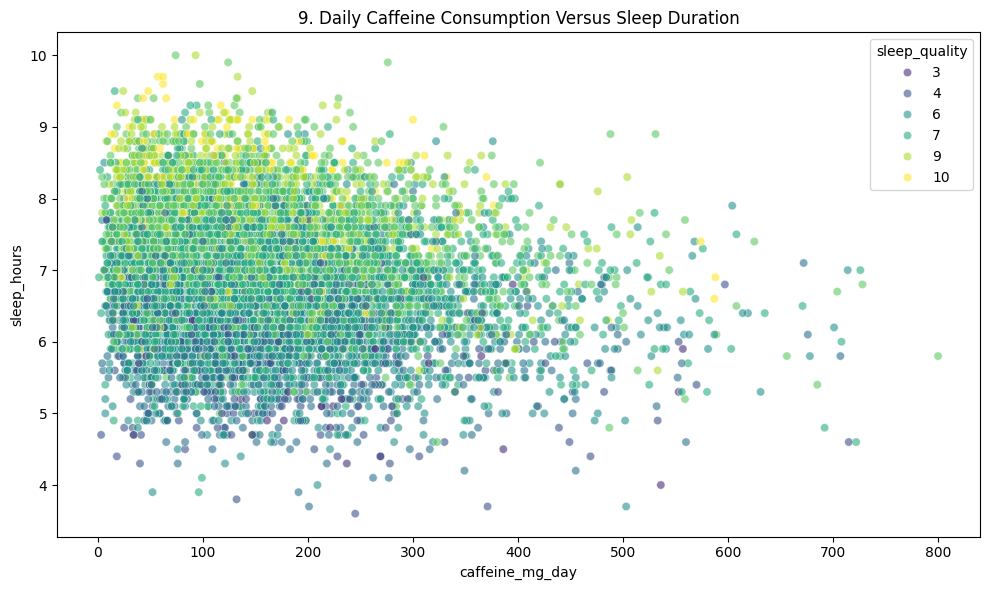

In [21]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='caffeine_mg_day', y='sleep_hours', hue='sleep_quality', palette='viridis', alpha=0.6)
plt.title(f'{plot_no}. Daily Caffeine Consumption Versus Sleep Duration')
show_fig()
plot_no += 1

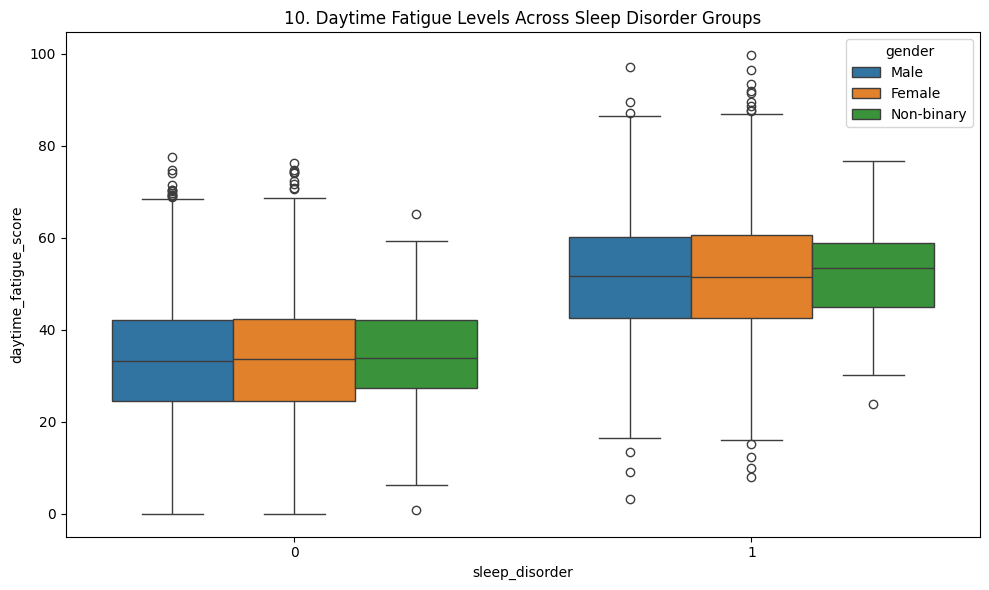

In [22]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='sleep_disorder', y='daytime_fatigue_score', hue='gender')
plt.title(f'{plot_no}. Daytime Fatigue Levels Across Sleep Disorder Groups')
show_fig()
plot_no += 1

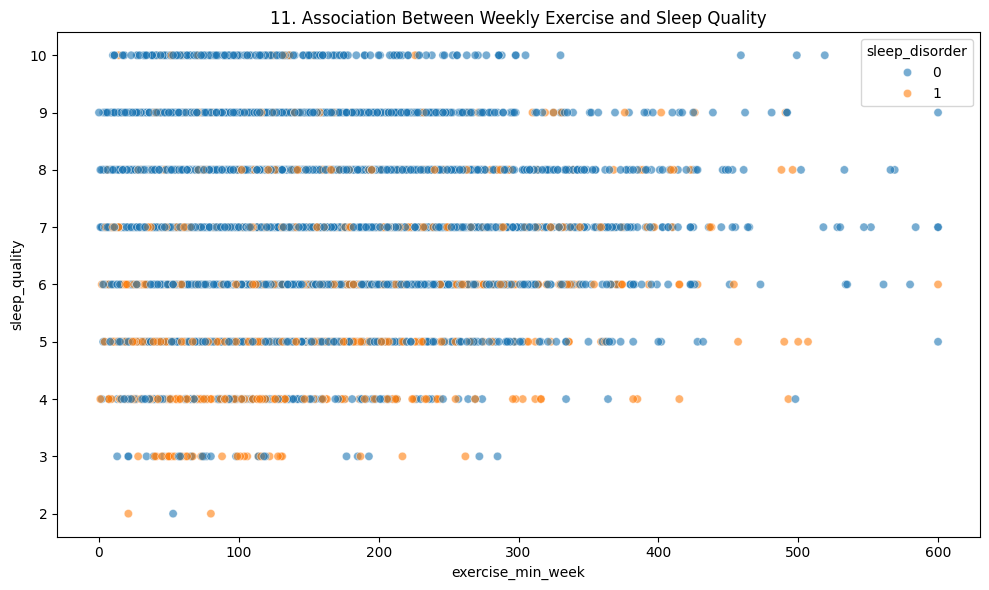

In [23]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='exercise_min_week', y='sleep_quality', hue='sleep_disorder', alpha=0.6)
plt.title(f'{plot_no}. Association Between Weekly Exercise and Sleep Quality')
show_fig()
plot_no += 1

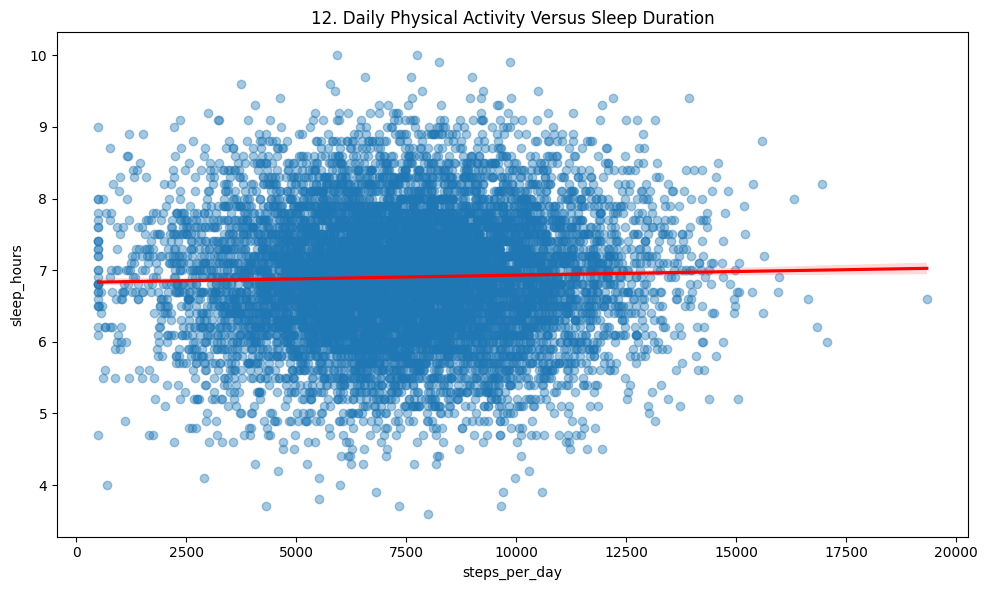

In [24]:
fig = plt.figure(figsize=(10,6))
sns.regplot(data=df, x='steps_per_day', y='sleep_hours', scatter_kws={'alpha':0.4}, line_kws={'color':'red'})
plt.title(f'{plot_no}. Daily Physical Activity Versus Sleep Duration')
show_fig()
plot_no += 1

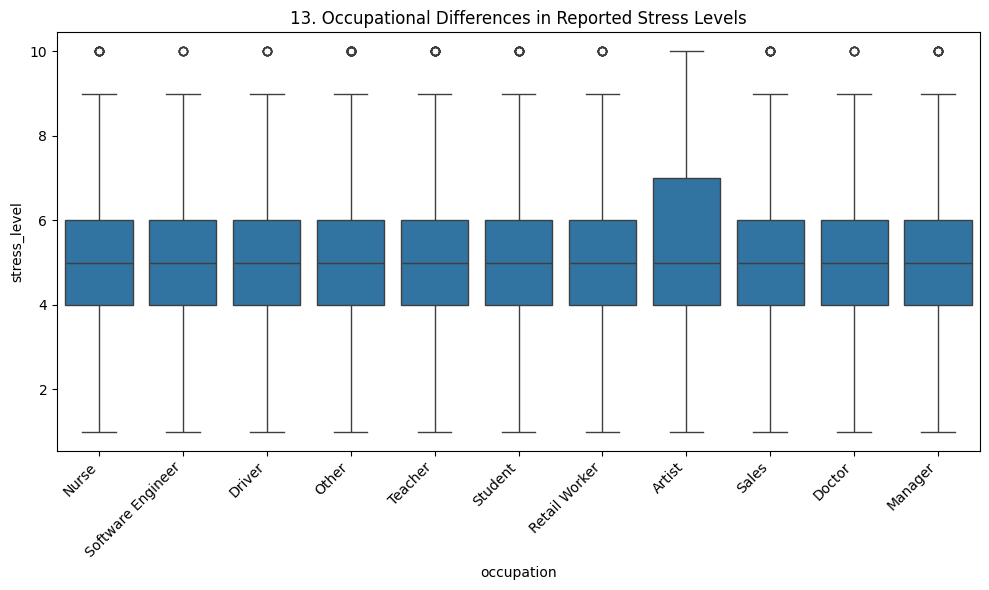

In [25]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='occupation', y='stress_level')
plt.xticks(rotation=45, ha='right')
plt.title(f'{plot_no}. Occupational Differences in Reported Stress Levels')
show_fig()
plot_no += 1

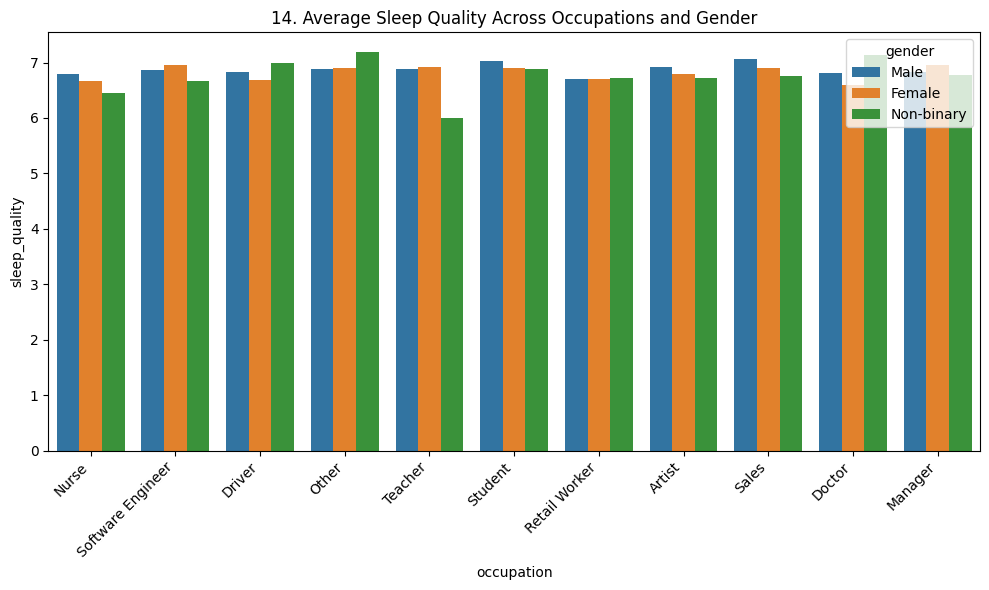

In [26]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='occupation', y='sleep_quality', hue='gender', errorbar=None)
plt.xticks(rotation=45, ha='right')
plt.title(f'{plot_no}. Average Sleep Quality Across Occupations and Gender')
show_fig()
plot_no += 1

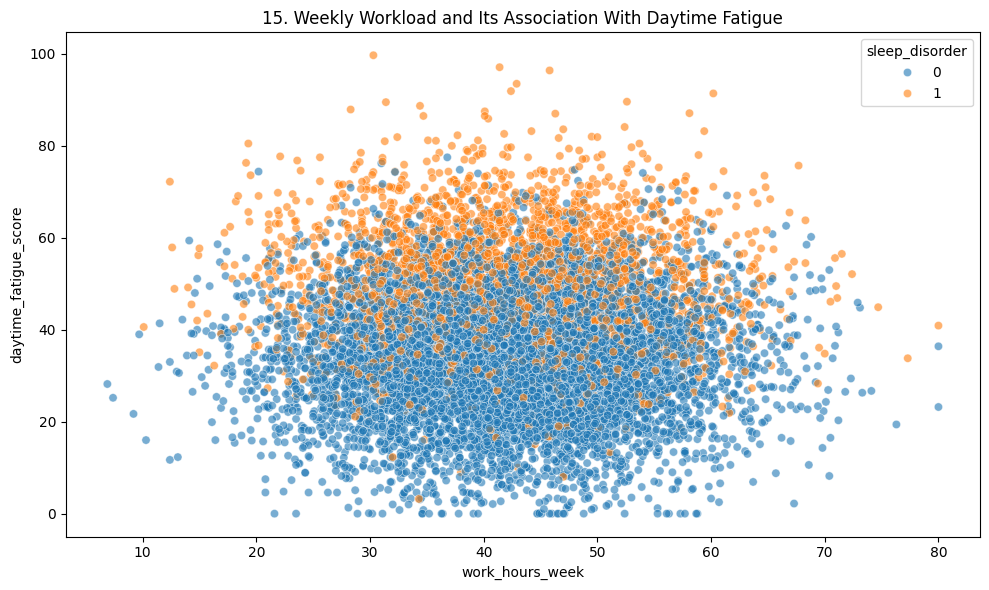

In [27]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='work_hours_week', y='daytime_fatigue_score', hue='sleep_disorder', alpha=0.6)
plt.title(f'{plot_no}. Weekly Workload and Its Association With Daytime Fatigue')
show_fig()
plot_no += 1

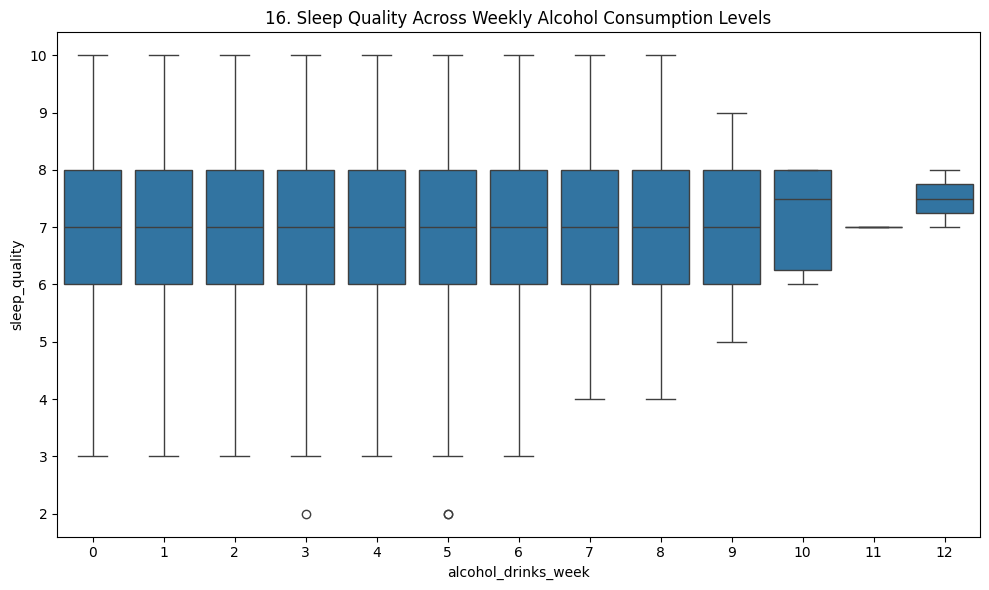

In [28]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='alcohol_drinks_week', y='sleep_quality')
plt.title(f'{plot_no}. Sleep Quality Across Weekly Alcohol Consumption Levels')
show_fig()
plot_no += 1

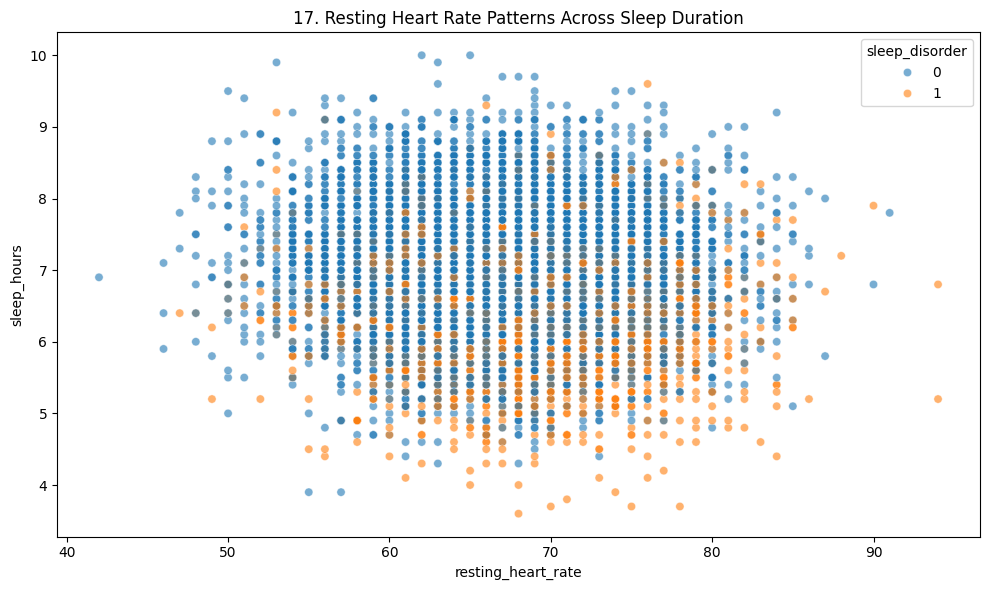

In [29]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='resting_heart_rate', y='sleep_hours', hue='sleep_disorder', alpha=0.6)
plt.title(f'{plot_no}. Resting Heart Rate Patterns Across Sleep Duration')
show_fig()
plot_no += 1

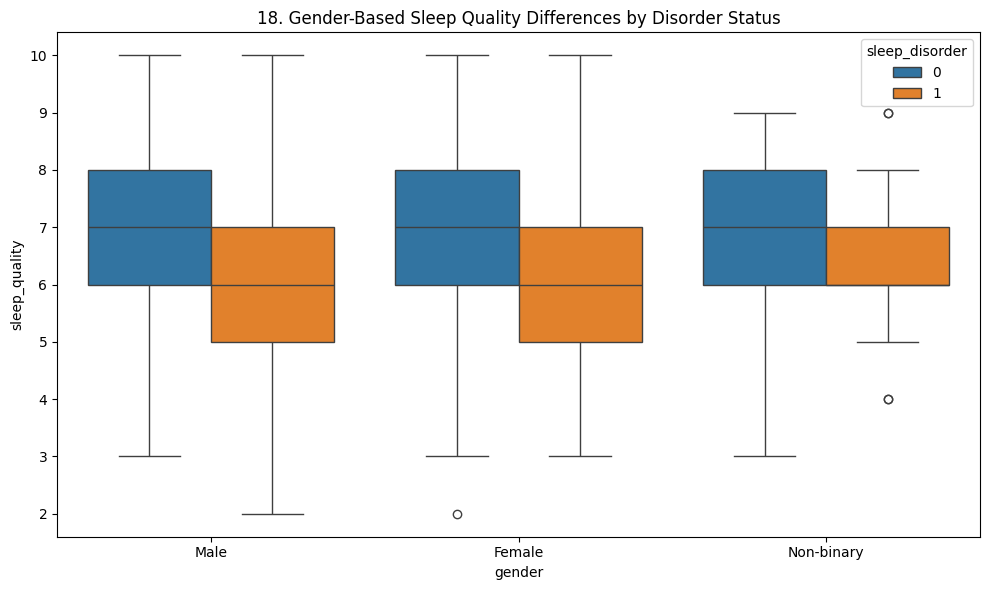

In [30]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='gender', y='sleep_quality', hue='sleep_disorder')
plt.title(f'{plot_no}. Gender-Based Sleep Quality Differences by Disorder Status')
show_fig()
plot_no += 1

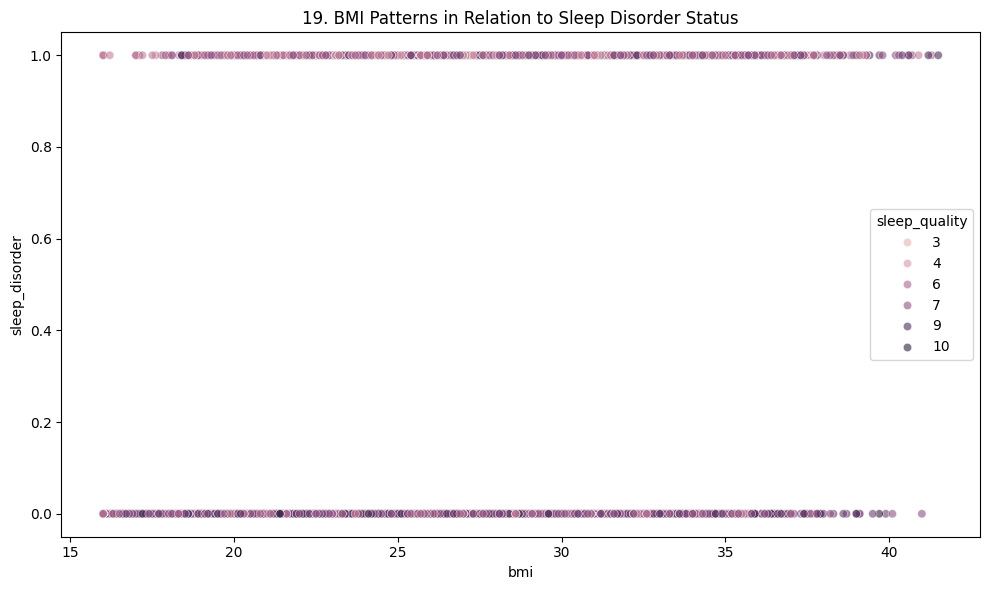

In [31]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='bmi', y='sleep_disorder', hue='sleep_quality', alpha=0.6)
plt.title(f'{plot_no}. BMI Patterns in Relation to Sleep Disorder Status')
show_fig()
plot_no += 1

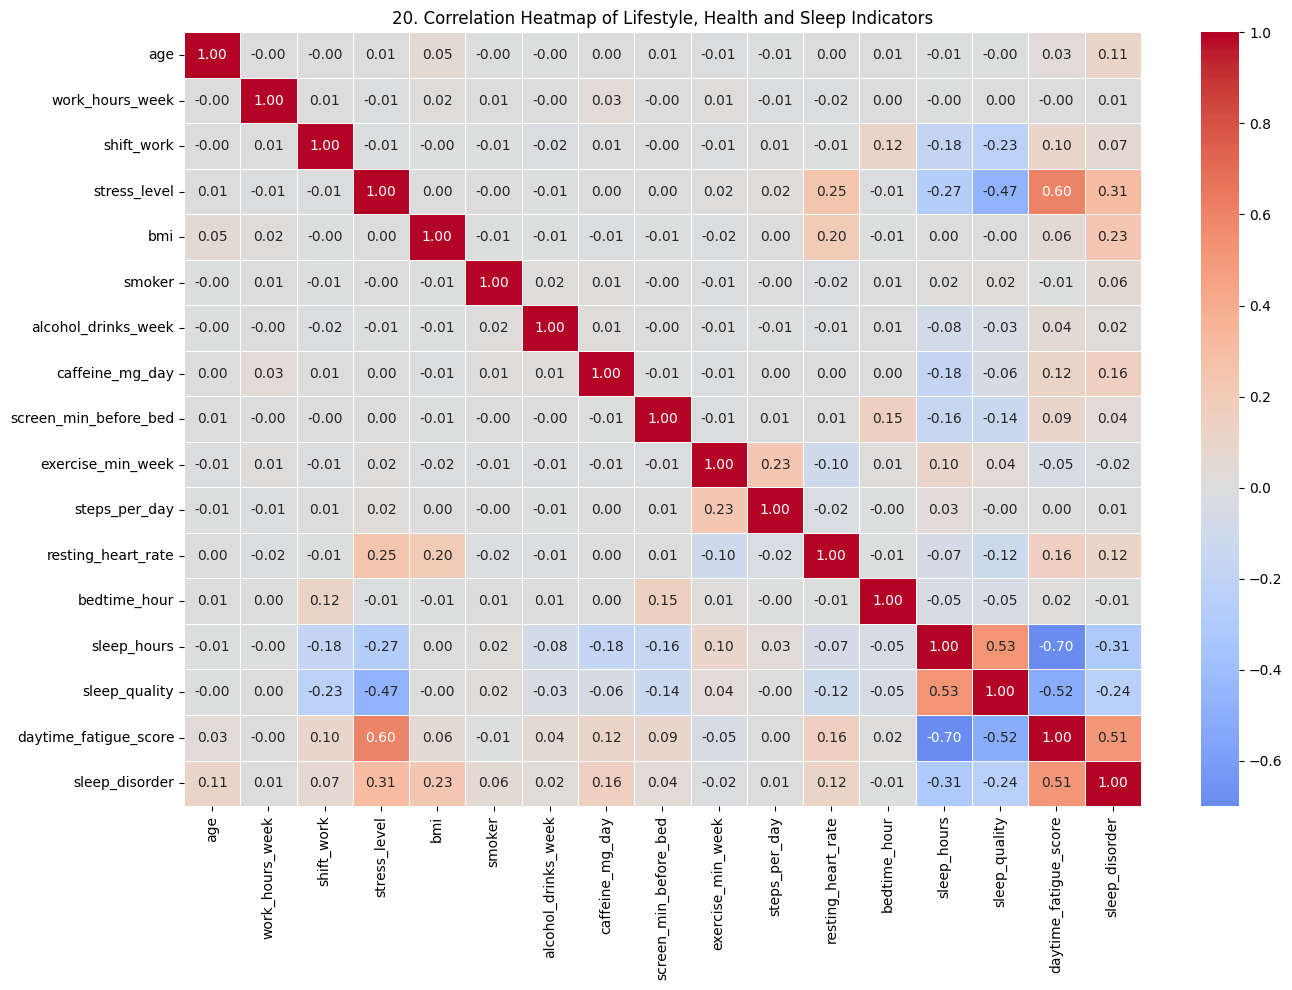

In [32]:
corr = df.select_dtypes(include='number').drop(columns=['person_id'], errors='ignore').corr()
fig = plt.figure(figsize=(14,10))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, center=0)
plt.title(f'{plot_no}. Correlation Heatmap of Lifestyle, Health and Sleep Indicators')
show_fig()
plot_no += 1

# Model Training

## Separate features and target

In [33]:
X = df.drop(columns=['sleep_disorder', 'person_id'])
y = df['sleep_disorder']

## Identify numerical and categorical columns

In [34]:
num_cols = X.select_dtypes(include=np.number).columns
cat_cols = X.select_dtypes(exclude=np.number).columns

## Preprocess numerical features

In [35]:
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

## Preprocess categorical features

In [36]:
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

## Combine preprocessing

In [37]:
preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

## Create the model

In [38]:
model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', HistGradientBoostingClassifier(
        max_iter=200,
        learning_rate=0.08,
        max_leaf_nodes=20,
        l2_regularization=1.0,
        random_state=42
    ))
])

## Split dataset

In [39]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

## Train model

In [40]:
model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


## Generate predictions

In [41]:
y_pred = model.predict(X_test)

## Evaluate model

In [42]:
print("Model: HistGradientBoostingClassifier")
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

Model: HistGradientBoostingClassifier
Accuracy: 83.45 %

Classification Report:

              precision    recall  f1-score   support

           0       0.86      0.93      0.89      1500
           1       0.72      0.56      0.63       500

    accuracy                           0.83      2000
   macro avg       0.79      0.74      0.76      2000
weighted avg       0.83      0.83      0.83      2000



## Plot confusion matrix

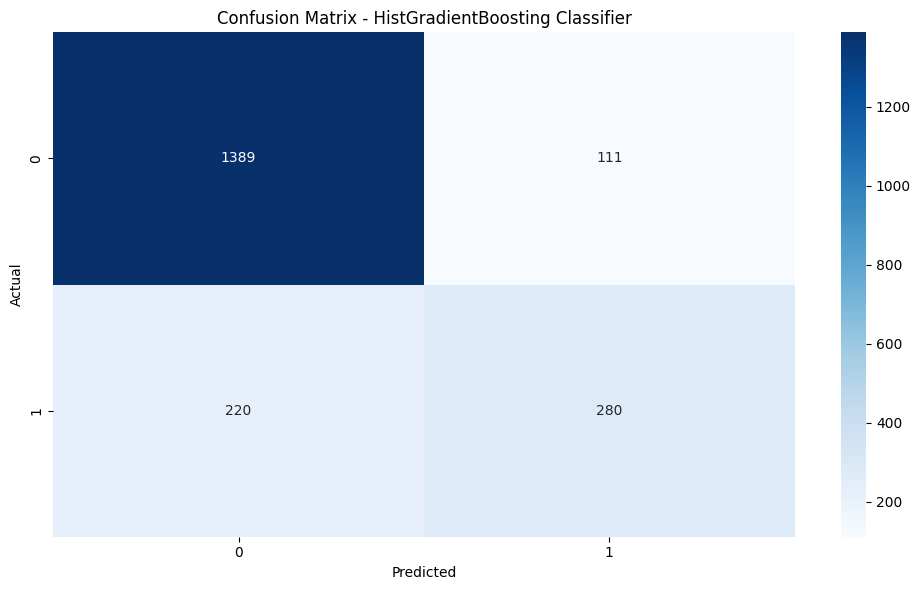

In [43]:
fig = plt.figure(figsize=(10,6))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=model.classes_,
            yticklabels=model.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - HistGradientBoosting Classifier')
show_fig()